# Regulated Pure Pursuit

Track a curved indoor path while adjusting speed for curvature, obstacle proximity and the remaining distance.

The target point sits a velocity-scaled arc length ahead. Its lateral displacement in the robot frame determines curvature. Speed is capped by curvature, geometric clearance and goal proximity. A forward projection can request a stop if the modelled footprint intersects an obstacle. This small forward-only implementation follows the ideas in the regulated pure pursuit paper.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from control import regulated_track
from matplotlib.patches import Circle

## Track the reference and examine the speed trace

The centreline, circular obstacle map and robot radius are known. Clearance is measured from the footprint boundary. The simulation uses a discrete forward collision check.

Goal error 0.070 m | cross-track RMS 0.038 m | minimum sampled clearance 0.214 m


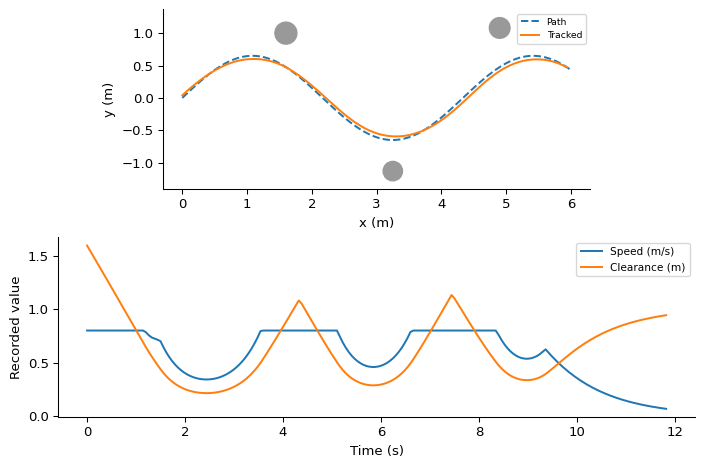

In [2]:
s = np.linspace(0, 6, 361)
path = np.c_[s, 0.65 * np.sin(1.45 * s)]
obs = [
    (np.array([1.6, 1.0]), 0.17),
    (np.array([3.25, -1.13]), 0.15),
    (np.array([4.9, 1.08]), 0.16),
]
track, speed, clear, error = regulated_track(path, obs)
final = np.linalg.norm(track[-1, :2] - path[-1])
print(
    f"Goal error {final:.3f} m | cross-track RMS {np.sqrt(np.mean(error**2)):.3f} m | minimum sampled clearance {clear.min():.3f} m"
)
assert final < 0.08 and clear.min() > 0
fig, (a, b) = plt.subplots(2, 1, figsize=(7.3, 4.8), constrained_layout=True)
a.plot(*path.T, "--", label="Path")
a.plot(*track[:, :2].T, label="Tracked")
for centre, r in obs:
    a.add_patch(Circle(centre, r, color="0.6"))
a.set(aspect="equal", xlabel="x (m)", ylabel="y (m)")
a.legend(fontsize=7)
t = 0.06 * np.arange(len(speed))
b.plot(t, speed, label="Speed (m/s)")
b.plot(t, clear, label="Clearance (m)")
b.set(xlabel="Time (s)", ylabel="Recorded value")
b.legend(fontsize=8)
plt.show()

## Interpreting the result

A positive clearance is a result for this map and time sampling. This lab uses Euclidean distances and a circular footprint. The Nav2 controller also supports costmap and platform-specific settings.

## Exercise

Move one obstacle towards the reference and compare speed reduction with the location of the predicted stop.

## References

[Macenski et al., Regulated Pure Pursuit for Robot Path Tracking (2023)](https://arxiv.org/abs/2305.20026)

[Nav2, regulated pure pursuit](https://docs.nav2.org/configuration/packages/configuring-regulated-pp.html)